In [1]:
#el objetivo de este notebook es crear un df con cada fila correspondiente a un sistema planetario
#el analisis se centrara en los planetas de periodo corto y pequeños ya que 
#existe una predominancia en la brecha de investigaciones realizadas al respecto al momento. 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

plt.style.use("seaborn-v0_8")

df = pd.read_csv("../data_processed/03_catalogo_con_parametros_derivados.csv")

df.shape

(6267, 44)

In [2]:
#filtrar por planetas pequeños/intermedios de periodo corto y datos de metalicidad y radio/periodo disponible

df_candidatos = df[
    df["hostname"].notna() &
    df["pl_name"].notna() &
    df["pl_rade"].notna() &
    df["pl_orbper"].notna() &
    df["st_met"].notna() &
    df["st_mass"].notna() &
    (df["pl_rade"] >= 1.0) &
    (df["pl_rade"] <= 4.0) &
    (df["pl_orbper"] < 100)
].copy()

df_candidatos.shape

(3238, 44)

In [3]:
#crear una columna con n planetas por sistema

conteo_planetas_por_sistema = (
    df_candidatos
    .groupby("hostname")
    .size()
    .reset_index(name="N_pl_candidatos")
    .sort_values("N_pl_candidatos", ascending=False)
)

conteo_planetas_por_sistema.head(20)

,hostname,N_pl_candidatos
1888,Kepler-80,6
88,HD 110067,6
2174,TOI-178,6
202,K2-138,6
1672,Kepler-55,5
1080,Kepler-169,5
86,HD 108236,5
2107,TOI-1136,5
2276,TOI-5624,5
1925,Kepler-84,5


In [5]:
# Seleccionar sistemas con al menos 2 planetas candidatos

sistemas_multiplanetarios = conteo_planetas_por_sistema[
    conteo_planetas_por_sistema["N_pl_candidatos"] >= 2
].copy()

print("Sistemas con >=2 planetas candidatos:", len(sistemas_multiplanetarios))
print("Planetas en esos sistemas:", sistemas_multiplanetarios["N_pl_candidatos"].sum())

Sistemas con >=2 planetas candidatos: 615
Planetas en esos sistemas: 1513


In [6]:
hosts_multi = sistemas_multiplanetarios["hostname"].tolist()

df_multi = df_candidatos[
    df_candidatos["hostname"].isin(hosts_multi)
].copy()

df_multi.shape

(1513, 44)

In [7]:
df_multi.groupby("hostname").size().describe()

count    615.000000
mean       2.460163
std        0.772885
min        2.000000
25%        2.000000
50%        2.000000
75%        3.000000
max        6.000000
dtype: float64

In [8]:
#crear una nueva funcion para resumir un sistema planetario en una fila 
#los planetas se ordenan por periodo orbital

def resumir_sistema(grupo):
    
    grupo = grupo.sort_values("pl_orbper").copy()
    
    periodos = grupo["pl_orbper"].values
    radios = grupo["pl_rade"].values
    
    razones_periodo = periodos[1:] / periodos[:-1]
    
    return pd.Series({
        "N_planets": len(grupo),
        "P_min": np.min(periodos),
        "P_max": np.max(periodos),
        "period_span": np.max(periodos) / np.min(periodos),
        "period_ratios": list(razones_periodo),
        "median_period_ratio": np.median(razones_periodo),
        "max_period_ratio": np.max(razones_periodo),
        "gapped": int(np.any(razones_periodo > 5)),
        "radio_mediano_sistema": np.median(radios),
        "st_met": grupo["st_met"].median(),
        "st_mass": grupo["st_mass"].median()
    })

In [9]:
df_sistemas = (
    df_multi
    .groupby("hostname")
    .apply(resumir_sistema)
    .reset_index()
)

df_sistemas.shape

(615, 12)

In [10]:
df_sistemas.head()

,hostname,N_planets,P_min,P_max,period_span,period_ratios,median_period_ratio,max_period_ratio,gapped,radio_mediano_sistema,st_met,st_mass
0,55 Cnc B,2,6.799400,33.747000,4.963232,[4.963232049886755],4.963232,4.963232,0,1.925000,0.160,0.2600
1,AU Mic,2,12.735960,18.859023,1.480770,[1.4807696475177372],1.480770,1.480770,0,1.905000,0.120,0.5725
2,CoRoT-7,2,0.853592,3.698000,4.332282,[4.3322824053464535],4.332282,4.332282,0,2.255675,0.055,0.8595
3,DMPP-6,2,7.602700,36.441000,4.793166,[4.79316558591027],4.793166,4.793166,0,3.010000,0.320,1.0790
4,EPIC 206024342,3,0.911724,14.647531,16.065751,"[4.943996209379154, 3.24954764883884]",4.096772,4.943996,0,1.700000,-0.220,0.9280


In [21]:
print("Número de sistemas:", len(df_sistemas))
print("Columnas:", df_sistemas.columns.tolist())
print("Sistemas con N_planetas < 2:", (df_sistemas["N_planets"] < 2).sum())
print("Sistemas con period_span <= 1:", (df_sistemas["period_span"] <= 1).sum())
print("Sistemas con median_period_ratio <= 1:", (df_sistemas["median_period_ratio"] <= 1).sum())
print("Sistemas con max_period_ratio <= 1:", (df_sistemas["max_period_ratio"] <= 1).sum())
print("Sistemas gapped:", df_sistemas["gapped"].sum())

Número de sistemas: 615
Columnas: ['hostname', 'N_planets', 'P_min', 'P_max', 'period_span', 'period_ratios', 'median_period_ratio', 'max_period_ratio', 'gapped', 'radio_mediano_sistema', 'st_met', 'st_mass']
Sistemas con N_planetas < 2: 0
Sistemas con period_span <= 1: 0
Sistemas con median_period_ratio <= 1: 0
Sistemas con max_period_ratio <= 1: 0
Sistemas gapped: 85


In [ ]:
df_sistemas.to_csv("../data_processed/04_sistemas_planetarios.csv", index=False)

In [12]:
tabla_criterios = pd.DataFrame({
    "paso": [
        "Catálogo limpio base",
        "Con hostname, pl_name, radio, período, [Fe/H] y masa estelar disponibles",
        "Radio planetario entre 1 y 4 R_earth",
        "Período orbital menor a 100 días",
        "Sistemas con al menos 2 planetas candidatos",
        "Planetas dentro de sistemas finales",
        "Sistemas finales"
    ],
    "unidad": [
        "planetas",
        "planetas",
        "planetas",
        "planetas",
        "sistemas",
        "planetas",
        "sistemas"
    ],
    "N": [
        len(df),
        len(df[
            df["hostname"].notna() &
            df["pl_name"].notna() &
            df["pl_rade"].notna() &
            df["pl_orbper"].notna() &
            df["st_met"].notna() &
            df["st_mass"].notna()
        ]),
        len(df[
            df["hostname"].notna() &
            df["pl_name"].notna() &
            df["pl_rade"].notna() &
            df["pl_orbper"].notna() &
            df["st_met"].notna() &
            df["st_mass"].notna() &
            (df["pl_rade"] >= 1.0) &
            (df["pl_rade"] <= 4.0)
        ]),
        len(df_candidatos),
        len(sistemas_multiplanetarios),
        len(df_multi),
        len(df_sistemas)
    ]
})

tabla_criterios

,paso,unidad,N
0,Catálogo limpio base,planetas,6267
1,"Con hostname, pl_name, radio, período, [Fe/H] ...",planetas,5578
2,Radio planetario entre 1 y 4 R_earth,planetas,3371
3,Período orbital menor a 100 días,planetas,3238
4,Sistemas con al menos 2 planetas candidatos,sistemas,615
5,Planetas dentro de sistemas finales,planetas,1513
6,Sistemas finales,sistemas,615


In [13]:
tabla_criterios.to_csv("../tables/tabla_criterios_seleccion_sistemas.csv", index=False)

In [23]:
resumen_sistemas = pd.DataFrame({
    "cantidad": [
        len(df_sistemas),
        df_sistemas["N_planets"].sum(),
        df_sistemas["gapped"].sum(),
        (df_sistemas["gapped"].mean() * 100),
        df_sistemas["N_planets"].median(),
        df_sistemas["median_period_ratio"].median(),
        df_sistemas["max_period_ratio"].median()
    ]
}, index=[
    "sistemas_finales",
    "planetas_en_sistemas_finales",
    "sistemas_gapped",
    "porcentaje_gapped",
    "mediana_N_planetas_por_sistema",
    "mediana_median_period_ratio",
    "mediana_max_period_ratio"
])

resumen_sistemas

,cantidad
sistemas_finales,615.000000
planetas_en_sistemas_finales,1513.000000
sistemas_gapped,85.000000
porcentaje_gapped,13.821138
mediana_N_planetas_por_sistema,2.000000
mediana_median_period_ratio,2.342518
mediana_max_period_ratio,2.537586


In [28]:
# Distribución de multiplicidad de la muestra final de sistemas

def agrupar_multiplicidad(n):
    if n == 2:
        return "N=2"
    elif n == 3:
        return "N=3"
    elif n == 4:
        return "N=4"
    elif n == 5:
        return "N=5"
    else:
        return "N>=6"

df_sistemas["multiplicidad_grupo"] = df_sistemas["N_planets"].apply(agrupar_multiplicidad)

tabla_multiplicidad = (
    df_sistemas["multiplicidad_grupo"]
    .value_counts()
    .reindex(["N=2", "N=3", "N=4", "N=5", "N>=6"])
    .reset_index()
)

tabla_multiplicidad.columns = ["multiplicidad", "N_sistemas"]

tabla_multiplicidad["porcentaje"] = (
    100 * tabla_multiplicidad["N_sistemas"] / tabla_multiplicidad["N_sistemas"].sum()
).round(2)

tabla_multiplicidad

,multiplicidad,N_sistemas,porcentaje
0,N=2,415,67.48
1,N=3,137,22.28
2,N=4,47,7.64
3,N=5,12,1.95
4,N>=6,4,0.65


In [26]:
tabla_multiplicidad.to_csv("../tables/tabla_multiplicidad_sistemas.csv", index=False)

In [27]:
tabla_disponibilidad_planetas = pd.DataFrame({
    "variable": [
        "st_met",
        "st_mass",
        "st_teff",
        "pl_rade",
        "pl_bmasse",
        "densidad_calculada"
    ],
    "N_planetas_disponibles": [
        df_multi["st_met"].notna().sum(),
        df_multi["st_mass"].notna().sum(),
        df_multi["st_teff"].notna().sum(),
        df_multi["pl_rade"].notna().sum(),
        df_multi["pl_bmasse"].notna().sum(),
        df_multi["densidad_calculada"].notna().sum()
    ],
    "N_planetas_total": len(df_multi)
})

tabla_disponibilidad_planetas["porcentaje_disponible"] = (
    100 * tabla_disponibilidad_planetas["N_planetas_disponibles"] /
    tabla_disponibilidad_planetas["N_planetas_total"]
).round(2)

tabla_disponibilidad_planetas

,variable,N_planetas_disponibles,N_planetas_total,porcentaje_disponible
0,st_met,1513,1513,100.0
1,st_mass,1513,1513,100.0
2,st_teff,1513,1513,100.0
3,pl_rade,1513,1513,100.0
4,pl_bmasse,1513,1513,100.0
5,densidad_calculada,1513,1513,100.0


In [29]:
def clasificar_origen_sistema(grupo):
    facilities = grupo["disc_facility"].astype(str).str.lower()
    metodos = grupo["discoverymethod"].astype(str).str.lower()
    
    tiene_kepler = facilities.str.contains("kepler", na=False).any()
    tiene_tess = facilities.str.contains("tess", na=False).any()
    
    transit_only = (
        (grupo["tran_flag"] == 1).all() and
        (grupo["rv_flag"] == 0).all() and
        (grupo["micro_flag"] == 0).all() and
        (grupo["ima_flag"] == 0).all()
    )
    
    tiene_rv = (grupo["rv_flag"] == 1).any() or metodos.str.contains("radial velocity", na=False).any()
    
    if tiene_kepler:
        return "Kepler"
    elif tiene_tess:
        return "TESS"
    elif transit_only:
        return "transit_only"
    elif tiene_rv:
        return "RV"
    else:
        return "otros"


origen_sistemas = (
    df_multi
    .groupby("hostname")
    .apply(clasificar_origen_sistema)
    .reset_index(name="origen_observacional")
)

origen_sistemas.head()

,hostname,origen_observacional
0,55 Cnc B,RV
1,AU Mic,TESS
2,CoRoT-7,RV
3,DMPP-6,RV
4,EPIC 206024342,transit_only


In [30]:
df_sistemas = df_sistemas.merge(origen_sistemas, on="hostname", how="left")

tabla_origen_sistemas = (
    df_sistemas["origen_observacional"]
    .value_counts()
    .reset_index()
)

tabla_origen_sistemas.columns = ["origen_observacional", "N_sistemas"]

tabla_origen_sistemas["porcentaje"] = (
    100 * tabla_origen_sistemas["N_sistemas"] / len(df_sistemas)
).round(2)

tabla_origen_sistemas

,origen_observacional,N_sistemas,porcentaje
0,Kepler,389,63.25
1,TESS,95,15.45
2,transit_only,67,10.89
3,RV,64,10.41


In [31]:
tabla_origen_sistemas.to_csv("../tables/tabla_origen_observacional_sistemas.csv", index=False)

df_sistemas.to_csv("../data_processed/04_sistemas_planetarios.csv", index=False)

In [33]:
sample_bookkeeping = pd.DataFrame({
    "bloque": [
        "seleccion",
        "seleccion",
        "seleccion",
        "seleccion",
        "seleccion",
        "seleccion",
        "resumen_final",
        "resumen_final",
        "resumen_final",
        "resumen_final",
        "multiplicidad",
        "multiplicidad",
        "multiplicidad",
        "multiplicidad",
        "multiplicidad",
        "origen_observacional",
        "origen_observacional",
        "origen_observacional",
        "origen_observacional"
    ],
    "criterio_o_categoria": [
        "Catalogo limpio base",
        "Parametros necesarios disponibles",
        "Radio planetario entre 1 y 4 R_earth",
        "Periodo orbital menor a 100 dias",
        "Sistemas con al menos 2 planetas candidatos",
        "Planetas dentro de sistemas finales",
        "Sistemas finales",
        "Planetas en sistemas finales",
        "Sistemas gapped",
        "Porcentaje gapped",
        "N=2",
        "N=3",
        "N=4",
        "N=5",
        "N>=6",
        "Kepler",
        "TESS",
        "transit_only",
        "RV"
    ],
    "unidad": [
        "planetas",
        "planetas",
        "planetas",
        "planetas",
        "sistemas",
        "planetas",
        "sistemas",
        "planetas",
        "sistemas",
        "porcentaje",
        "sistemas",
        "sistemas",
        "sistemas",
        "sistemas",
        "sistemas",
        "sistemas",
        "sistemas",
        "sistemas",
        "sistemas"
    ],
    "N_o_valor": [
        6267,
        5578,
        3371,
        3238,
        615,
        1513,
        len(df_sistemas),
        df_sistemas["N_planets"].sum(),
        df_sistemas["gapped"].sum(),
        round(df_sistemas["gapped"].mean() * 100, 2),
        int(tabla_multiplicidad.loc[tabla_multiplicidad["multiplicidad"] == "N=2", "N_sistemas"].iloc[0]),
        int(tabla_multiplicidad.loc[tabla_multiplicidad["multiplicidad"] == "N=3", "N_sistemas"].iloc[0]),
        int(tabla_multiplicidad.loc[tabla_multiplicidad["multiplicidad"] == "N=4", "N_sistemas"].iloc[0]),
        int(tabla_multiplicidad.loc[tabla_multiplicidad["multiplicidad"] == "N=5", "N_sistemas"].iloc[0]),
        int(tabla_multiplicidad.loc[tabla_multiplicidad["multiplicidad"] == "N>=6", "N_sistemas"].iloc[0]),
        int(tabla_origen_sistemas.loc[tabla_origen_sistemas["origen_observacional"] == "Kepler", "N_sistemas"].iloc[0]),
        int(tabla_origen_sistemas.loc[tabla_origen_sistemas["origen_observacional"] == "TESS", "N_sistemas"].iloc[0]),
        int(tabla_origen_sistemas.loc[tabla_origen_sistemas["origen_observacional"] == "transit_only", "N_sistemas"].iloc[0]),
        int(tabla_origen_sistemas.loc[tabla_origen_sistemas["origen_observacional"] == "RV", "N_sistemas"].iloc[0])
    ]
})

sample_bookkeeping

,bloque,criterio_o_categoria,unidad,N_o_valor
0,seleccion,Catalogo limpio base,planetas,6267.00
1,seleccion,Parametros necesarios disponibles,planetas,5578.00
2,seleccion,Radio planetario entre 1 y 4 R_earth,planetas,3371.00
3,seleccion,Periodo orbital menor a 100 dias,planetas,3238.00
4,seleccion,Sistemas con al menos 2 planetas candidatos,sistemas,615.00
5,seleccion,Planetas dentro de sistemas finales,planetas,1513.00
6,resumen_final,Sistemas finales,sistemas,615.00
7,resumen_final,Planetas en sistemas finales,planetas,1513.00
8,resumen_final,Sistemas gapped,sistemas,85.00
9,resumen_final,Porcentaje gapped,porcentaje,13.82


In [36]:
#crear versiones logaritmicas de las variables de espaciamiento df_sistemas["log_median_period_ratio"] = np.log10(df_sistemas["median_period_ratio"])
# Estandarizar nombre de columna de multiplicidad
if "N_planets" in df_sistemas.columns and "N_planetas" not in df_sistemas.columns:
    df_sistemas = df_sistemas.rename(columns={"N_planets": "N_planetas"})

# Crear variables logarítmicas de espaciamiento
df_sistemas["log_median_period_ratio"] = np.log10(df_sistemas["median_period_ratio"])
df_sistemas["log_max_period_ratio"] = np.log10(df_sistemas["max_period_ratio"])
df_sistemas["log_period_span"] = np.log10(df_sistemas["period_span"])

df_sistemas[[
    "hostname",
    "st_met",
    "median_period_ratio",
    "log_median_period_ratio",
    "max_period_ratio",
    "gapped"
]].head()

,hostname,st_met,median_period_ratio,log_median_period_ratio,max_period_ratio,gapped
0,55 Cnc B,0.160,4.963232,0.695765,4.963232,0
1,AU Mic,0.120,1.480770,0.170488,1.480770,0
2,CoRoT-7,0.055,4.332282,0.636717,4.332282,0
3,DMPP-6,0.320,4.793166,0.680622,4.793166,0
4,EPIC 206024342,-0.220,4.096772,0.612442,4.943996,0


In [37]:
from scipy.stats import spearmanr

df_spacing = df_sistemas[
    df_sistemas["st_met"].notna() &
    df_sistemas["median_period_ratio"].notna() &
    df_sistemas["log_median_period_ratio"].notna()
].copy()

rho_median, p_median = spearmanr(
    df_spacing["st_met"],
    df_spacing["median_period_ratio"]
)

rho_log_median, p_log_median = spearmanr(
    df_spacing["st_met"],
    df_spacing["log_median_period_ratio"]
)

print("Spearman: [Fe/H] vs median_period_ratio")
print(f"N = {len(df_spacing)}")
print(f"rho = {rho_median:.4f}")
print(f"p-value = {p_median:.3e}")

print("\nSpearman: [Fe/H] vs log10(median_period_ratio)")
print(f"N = {len(df_spacing)}")
print(f"rho = {rho_log_median:.4f}")
print(f"p-value = {p_log_median:.3e}")

Spearman: [Fe/H] vs median_period_ratio
N = 615
rho = 0.0237
p-value = 5.579e-01

Spearman: [Fe/H] vs log10(median_period_ratio)
N = 615
rho = 0.0237
p-value = 5.579e-01


In [38]:
tabla_spearman_spacing = pd.DataFrame({
    "analisis": [
        "st_met_vs_median_period_ratio",
        "st_met_vs_log_median_period_ratio"
    ],
    "N": [
        len(df_spacing),
        len(df_spacing)
    ],
    "spearman_rho": [
        rho_median,
        rho_log_median
    ],
    "p_value": [
        p_median,
        p_log_median
    ]
})

tabla_spearman_spacing.to_csv(
    "../tables/tabla_spearman_metalicidad_spacing.csv",
    index=False
)

tabla_spearman_spacing

,analisis,N,spearman_rho,p_value
0,st_met_vs_median_period_ratio,615,0.023674,0.557891
1,st_met_vs_log_median_period_ratio,615,0.023674,0.557891


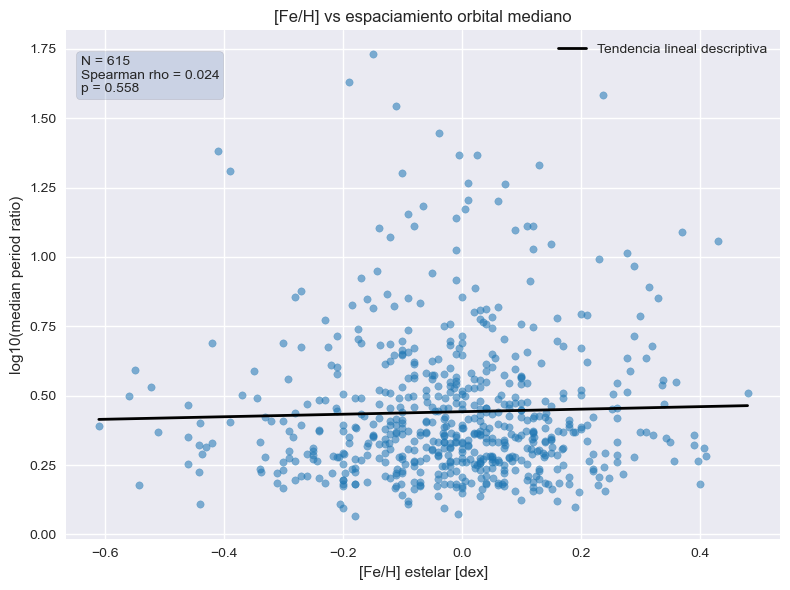

In [39]:
plt.figure(figsize=(8, 6))

plt.scatter(
    df_spacing["st_met"],
    df_spacing["log_median_period_ratio"],
    s=28,
    alpha=0.55,
    color="tab:blue"
)

# Línea descriptiva simple
coef = np.polyfit(
    df_spacing["st_met"],
    df_spacing["log_median_period_ratio"],
    1
)

x_line = np.linspace(
    df_spacing["st_met"].min(),
    df_spacing["st_met"].max(),
    100
)

y_line = coef[0] * x_line + coef[1]

plt.plot(
    x_line,
    y_line,
    color="black",
    linewidth=2,
    label="Tendencia lineal descriptiva"
)

plt.xlabel("[Fe/H] estelar [dex]")
plt.ylabel("log10(median period ratio)")
plt.title("[Fe/H] vs espaciamiento orbital mediano")

plt.text(
    0.02,
    0.95,
    f"N = {len(df_spacing)}\nSpearman rho = {rho_median:.3f}\np = {p_median:.3f}",
    transform=plt.gca().transAxes,
    verticalalignment="top",
    bbox=dict(boxstyle="round", alpha=0.2)
)

plt.legend()
plt.tight_layout()
plt.savefig("../figures/fig_metalicidad_vs_log_median_period_ratio.png", dpi=300)
plt.show()

In [40]:
# Bootstrap del coeficiente Spearman rho para [Fe/H] vs median_period_ratio

n_boot = 5000
rng = np.random.default_rng(42)

rho_boot = []

x = df_spacing["st_met"].values
y = df_spacing["median_period_ratio"].values
n = len(df_spacing)

for _ in range(n_boot):
    indices = rng.integers(0, n, size=n)
    rho_i, _ = spearmanr(x[indices], y[indices])
    rho_boot.append(rho_i)

rho_boot = np.array(rho_boot)

rho_ci_low = np.percentile(rho_boot, 2.5)
rho_ci_high = np.percentile(rho_boot, 97.5)

print(f"Spearman rho observado = {rho_median:.4f}")
print(f"IC 95% bootstrap = [{rho_ci_low:.4f}, {rho_ci_high:.4f}]")

Spearman rho observado = 0.0237
IC 95% bootstrap = [-0.0544, 0.1008]


In [41]:
tabla_met_gapped = (
    df_sistemas
    .groupby("gapped")["st_met"]
    .agg(
        N="count",
        mediana="median",
        Q1=lambda x: x.quantile(0.25),
        Q3=lambda x: x.quantile(0.75),
        minimo="min",
        maximo="max"
    )
)

tabla_met_gapped["IQR"] = tabla_met_gapped["Q3"] - tabla_met_gapped["Q1"]

tabla_met_gapped = tabla_met_gapped[
    ["N", "mediana", "Q1", "Q3", "IQR", "minimo", "maximo"]
].round(4)

tabla_met_gapped

,N,mediana,Q1,Q3,IQR,minimo,maximo
gapped,,,,,,,
0,530,-0.010,-0.11,0.09,0.20,-0.61,0.48
1,85,0.006,-0.11,0.11,0.22,-0.41,0.43


In [42]:
from scipy.stats import mannwhitneyu

grupo_no_gap = df_sistemas[df_sistemas["gapped"] == 0]["st_met"].dropna()
grupo_gap = df_sistemas[df_sistemas["gapped"] == 1]["st_met"].dropna()

U, p_mw = mannwhitneyu(
    grupo_no_gap,
    grupo_gap,
    alternative="two-sided"
)

n0 = len(grupo_no_gap)
n1 = len(grupo_gap)

# Tamaño de efecto rank-biserial correlation
# Usamos esta orientación: positivo si gapped=1 tiende a tener [Fe/H] mayor que gapped=0
rank_biserial = (2 * U) / (n0 * n1) - 1
rank_biserial = -rank_biserial

tabla_mannwhitney_gapped = pd.DataFrame({
    "comparacion": ["st_met_gapped_0_vs_1"],
    "N_gapped_0": [n0],
    "N_gapped_1": [n1],
    "mediana_gapped_0": [grupo_no_gap.median()],
    "mediana_gapped_1": [grupo_gap.median()],
    "diferencia_mediana_1_menos_0": [grupo_gap.median() - grupo_no_gap.median()],
    "U": [U],
    "p_value": [p_mw],
    "rank_biserial": [rank_biserial]
})

tabla_mannwhitney_gapped.round(6)

,comparacion,N_gapped_0,N_gapped_1,mediana_gapped_0,mediana_gapped_1,diferencia_mediana_1_menos_0,U,p_value,rank_biserial
0,st_met_gapped_0_vs_1,530,85,-0.01,0.006,0.016,21057.5,0.334656,0.06515


In [43]:
tabla_met_gapped.to_csv("../tables/tabla_metalicidad_por_gapped.csv")
tabla_mannwhitney_gapped.to_csv("../tables/tabla_mannwhitney_metalicidad_gapped.csv", index=False)

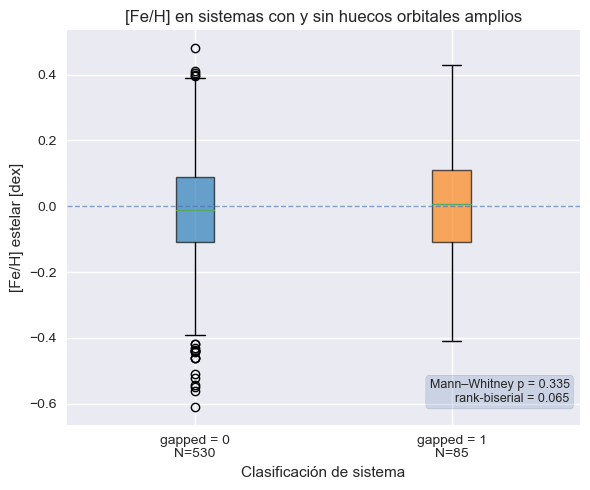

In [47]:
datos_gapped = [
    df_sistemas[df_sistemas["gapped"] == 0]["st_met"].dropna(),
    df_sistemas[df_sistemas["gapped"] == 1]["st_met"].dropna()
]

labels_gapped = [
    f"gapped = 0\nN={len(datos_gapped[0])}",
    f"gapped = 1\nN={len(datos_gapped[1])}"
]

plt.figure(figsize=(6, 5))

box = plt.boxplot(
    datos_gapped,
    labels=labels_gapped,
    patch_artist=True,
    showfliers=True
)

colores = ["tab:blue", "tab:orange"]

for patch, color in zip(box["boxes"], colores):
    patch.set_facecolor(color)
    patch.set_alpha(0.65)

plt.axhline(0, linestyle="--", linewidth=1, alpha=0.7)

plt.ylabel("[Fe/H] estelar [dex]")
plt.xlabel("Clasificación de sistema")
plt.title("[Fe/H] en sistemas con y sin huecos orbitales amplios")

plt.text(
    0.98,
    0.05,
    f"Mann–Whitney p = {p_mw:.3f}\nrank-biserial = {rank_biserial:.3f}",
    transform=plt.gca().transAxes,
    ha="right",
    va="bottom",
    fontsize=9,
    bbox=dict(boxstyle="round", alpha=0.2)
)

plt.tight_layout()
plt.savefig("../figures/fig_metalicidad_gapped_boxplot.png", dpi=300)
plt.show()

#No se observa una diferencia clara en [Fe/H] entre sistemas con y sin huecos orbitales amplios. 
#Las medianas son muy similares y la prueba de Mann–Whitney no indica una diferencia significativa 
#(p = 0.335), con un tamaño de efecto pequeño (rank-biserial = 0.065).

In [48]:
import statsmodels.api as sm

df_logit = df_sistemas[
    df_sistemas["gapped"].notna() &
    df_sistemas["st_met"].notna()
].copy()

X = df_logit[["st_met"]]
X = sm.add_constant(X)

y = df_logit["gapped"]

modelo_logit = sm.Logit(y, X).fit()

modelo_logit.summary()

Optimization terminated successfully.
         Current function value: 0.400016
         Iterations 6


<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:                 gapped   No. Observations:                  615
Model:                          Logit   Df Residuals:                      613
Method:                           MLE   Df Model:                            1
Date:                Mon, 17 Aug 2026   Pseudo R-squ.:                0.004200
Time:                        08:42:55   Log-Likelihood:                -246.01
converged:                       True   LL-Null:                       -247.05
Covariance Type:            nonrobust   LLR p-value:                    0.1497
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -1.8269      0.117    -15.596      0.000      -2.056      -1.597
st_met         0.9812      0.686      1.429      0.153      -0.364       2.327
==============================================================================
"""

In [49]:
odds_ratio = np.exp(modelo_logit.params["st_met"])
ci = modelo_logit.conf_int()
ci_odds = np.exp(ci.loc["st_met"])

print(f"Odds ratio = {odds_ratio:.3f}")
print(f"IC95% odds ratio = [{ci_odds[0]:.3f}, {ci_odds[1]:.3f}]")

Odds ratio = 2.668
IC95% odds ratio = [0.695, 10.243]


In [50]:
tabla_logit_gapped = pd.DataFrame({
    "modelo": ["gapped ~ st_met"],
    "N": [len(df_logit)],
    "coef_st_met": [modelo_logit.params["st_met"]],
    "p_value_st_met": [modelo_logit.pvalues["st_met"]],
    "odds_ratio_st_met": [odds_ratio],
    "OR_IC95_low": [ci_odds[0]],
    "OR_IC95_high": [ci_odds[1]],
    "pseudo_R2": [modelo_logit.prsquared]
})

tabla_logit_gapped.to_csv(
    "../tables/tabla_logit_metalicidad_gapped.csv",
    index=False
)

tabla_logit_gapped

,modelo,N,coef_st_met,p_value_st_met,odds_ratio_st_met,OR_IC95_low,OR_IC95_high,pseudo_R2
0,gapped ~ st_met,615,0.981176,0.152902,2.66759,0.694729,10.242893,0.0042


In [51]:
from scipy.stats import spearmanr

df_mass_arch = df_sistemas[
    df_sistemas["st_mass"].notna() &
    df_sistemas["median_period_ratio"].notna() &
    df_sistemas["max_period_ratio"].notna() &
    df_sistemas["period_span"].notna()
].copy()

variables_arquitectura = [
    "median_period_ratio",
    "max_period_ratio",
    "period_span"
]

resultados_mass_spearman = []

for var in variables_arquitectura:
    rho, p = spearmanr(df_mass_arch["st_mass"], df_mass_arch[var])
    
    resultados_mass_spearman.append({
        "variable_x": "st_mass",
        "variable_y": var,
        "N": len(df_mass_arch),
        "spearman_rho": rho,
        "p_value": p
    })

tabla_spearman_masa_arquitectura = pd.DataFrame(resultados_mass_spearman)

tabla_spearman_masa_arquitectura

,variable_x,variable_y,N,spearman_rho,p_value
0,st_mass,median_period_ratio,615,-0.110357,0.006152
1,st_mass,max_period_ratio,615,-0.117154,0.003621
2,st_mass,period_span,615,-0.138460,0.000575


In [52]:
tabla_spearman_masa_arquitectura.to_csv(
    "../tables/tabla_spearman_masa_estelar_arquitectura.csv",
    index=False
)

In [53]:
tabla_mass_gapped = (
    df_sistemas
    .groupby("gapped")["st_mass"]
    .agg(
        N="count",
        mediana="median",
        Q1=lambda x: x.quantile(0.25),
        Q3=lambda x: x.quantile(0.75),
        minimo="min",
        maximo="max"
    )
)

tabla_mass_gapped["IQR"] = tabla_mass_gapped["Q3"] - tabla_mass_gapped["Q1"]

tabla_mass_gapped = tabla_mass_gapped[
    ["N", "mediana", "Q1", "Q3", "IQR", "minimo", "maximo"]
].round(4)

tabla_mass_gapped

,N,mediana,Q1,Q3,IQR,minimo,maximo
gapped,,,,,,,
0,530,0.891,0.748,1.022,0.274,0.0898,1.650
1,85,0.855,0.635,0.954,0.319,0.1640,1.367


In [55]:
from scipy.stats import mannwhitneyu

grupo_mass_no_gap = df_sistemas[df_sistemas["gapped"] == 0]["st_mass"].dropna()
grupo_mass_gap = df_sistemas[df_sistemas["gapped"] == 1]["st_mass"].dropna()

U_mass, p_mass_mw = mannwhitneyu(
    grupo_mass_no_gap,
    grupo_mass_gap,
    alternative="two-sided"
)

n0_mass = len(grupo_mass_no_gap)
n1_mass = len(grupo_mass_gap)

# Tamaño de efecto rank-biserial
# Orientación: positivo si gapped=1 tiende a tener mayor st_mass que gapped=0
rank_biserial_mass = (2 * U_mass) / (n0_mass * n1_mass) - 1
rank_biserial_mass = -rank_biserial_mass

tabla_mannwhitney_mass_gapped = pd.DataFrame({
    "comparacion": ["st_mass_gapped_0_vs_1"],
    "N_gapped_0": [n0_mass],
    "N_gapped_1": [n1_mass],
    "mediana_gapped_0": [grupo_mass_no_gap.median()],
    "mediana_gapped_1": [grupo_mass_gap.median()],
    "diferencia_mediana_1_menos_0": [
        grupo_mass_gap.median() - grupo_mass_no_gap.median()
    ],
    "U": [U_mass],
    "p_value": [p_mass_mw],
    "rank_biserial": [rank_biserial_mass]
})

tabla_mannwhitney_mass_gapped.round(6)

#Se observa una diferencia débil pero estadísticamente significativa en la masa estelar entre sistemas con y sin huecos orbitales amplios. Los sistemas gapped = 1 tienden a orbitar estrellas ligeramente menos masivas, aunque el tamaño de efecto es pequeño.

,comparacion,N_gapped_0,N_gapped_1,mediana_gapped_0,mediana_gapped_1,diferencia_mediana_1_menos_0,U,p_value,rank_biserial
0,st_mass_gapped_0_vs_1,530,85,0.891,0.855,-0.036,26212.0,0.015341,-0.163685


In [56]:
tabla_mass_gapped.to_csv("../tables/tabla_masa_estelar_por_gapped.csv")
tabla_mannwhitney_mass_gapped.to_csv(
    "../tables/tabla_mannwhitney_masa_estelar_gapped.csv",
    index=False
)

In [57]:
tabla_resumen_masa_arquitectura = pd.DataFrame({
    "analisis": [
        "st_mass_vs_median_period_ratio",
        "st_mass_vs_max_period_ratio",
        "st_mass_vs_period_span",
        "st_mass_gapped_0_vs_1"
    ],
    "tipo_prueba": [
        "Spearman",
        "Spearman",
        "Spearman",
        "Mann-Whitney"
    ],
    "N": [
        len(df_mass_arch),
        len(df_mass_arch),
        len(df_mass_arch),
        n0_mass + n1_mass
    ],
    "estadistico": [
        tabla_spearman_masa_arquitectura.loc[
            tabla_spearman_masa_arquitectura["variable_y"] == "median_period_ratio",
            "spearman_rho"
        ].iloc[0],
        tabla_spearman_masa_arquitectura.loc[
            tabla_spearman_masa_arquitectura["variable_y"] == "max_period_ratio",
            "spearman_rho"
        ].iloc[0],
        tabla_spearman_masa_arquitectura.loc[
            tabla_spearman_masa_arquitectura["variable_y"] == "period_span",
            "spearman_rho"
        ].iloc[0],
        rank_biserial_mass
    ],
    "p_value": [
        tabla_spearman_masa_arquitectura.loc[
            tabla_spearman_masa_arquitectura["variable_y"] == "median_period_ratio",
            "p_value"
        ].iloc[0],
        tabla_spearman_masa_arquitectura.loc[
            tabla_spearman_masa_arquitectura["variable_y"] == "max_period_ratio",
            "p_value"
        ].iloc[0],
        tabla_spearman_masa_arquitectura.loc[
            tabla_spearman_masa_arquitectura["variable_y"] == "period_span",
            "p_value"
        ].iloc[0],
        p_mass_mw
    ],
    "interpretacion_breve": [
        "correlacion negativa debil",
        "correlacion negativa debil",
        "correlacion negativa debil",
        "gapped tiene masa estelar mediana ligeramente menor"
    ]
})

tabla_resumen_masa_arquitectura.to_csv(
    "../tables/tabla_resumen_masa_estelar_arquitectura.csv",
    index=False
)

tabla_resumen_masa_arquitectura

,analisis,tipo_prueba,N,estadistico,p_value,interpretacion_breve
0,st_mass_vs_median_period_ratio,Spearman,615,-0.110357,0.006152,correlacion negativa debil
1,st_mass_vs_max_period_ratio,Spearman,615,-0.117154,0.003621,correlacion negativa debil
2,st_mass_vs_period_span,Spearman,615,-0.138460,0.000575,correlacion negativa debil
3,st_mass_gapped_0_vs_1,Mann-Whitney,615,-0.163685,0.015341,gapped tiene masa estelar mediana ligeramente ...


In [58]:
def enriquecer_sistema(grupo):
    grupo = grupo.sort_values("pl_orbper").copy()
    
    periodos = grupo["pl_orbper"].values
    radios = grupo["pl_rade"].values
    
    period_ratios = periodos[1:] / periodos[:-1]
    radius_ratios = radios[1:] / radios[:-1]
    
    log_period_ratios = np.log(period_ratios)
    log_radius_ratios = np.log(radius_ratios)
    abs_log_radius_ratios = np.abs(log_radius_ratios)
    
    N = len(grupo)
    period_span = np.max(periodos) / np.min(periodos)
    
    return pd.Series({
        "N_planetas": N,
        
        # Periodos
        "P_min": np.min(periodos),
        "P_max": np.max(periodos),
        "period_span": period_span,
        "median_period_ratio": np.median(period_ratios),
        "max_period_ratio": np.max(period_ratios),
        "std_log_period_ratio": np.std(log_period_ratios, ddof=1) if N >= 3 else np.nan,
        "period_ratio_cv": np.std(period_ratios, ddof=1) / np.mean(period_ratios) if N >= 3 else np.nan,
        
        # Radios
        "median_radius": np.median(radios),
        "max_radius": np.max(radios),
        "min_radius": np.min(radios),
        "median_adjacent_radius_ratio": np.median(radius_ratios),
        "median_abs_log_radius_ratio": np.median(abs_log_radius_ratios),
        "outer_larger_fraction": np.mean(radius_ratios > 1),
        "radius_cv": np.std(radios, ddof=1) / np.mean(radios) if N >= 3 else np.nan,
        
        # Gradiente de radio con periodo
        "radius_gradient": np.polyfit(np.log(periodos), np.log(radios), 1)[0] if N >= 3 else np.nan,
        
        # Compactación proxy
        "compactness_proxy": (N - 1) / np.log(period_span),
        
        # Gap
        "gapped": int(np.any(period_ratios > 5)),
        
        # Propiedades estelares/sistema
        "st_met": grupo["st_met"].median(),
        "st_mass": grupo["st_mass"].median(),
        "st_teff": grupo["st_teff"].median(),
        "radio_mediano_sistema": np.median(radios)
    })


df_sistemas_enriquecido = (
    df_multi
    .groupby("hostname")
    .apply(enriquecer_sistema)
    .reset_index()
)

df_sistemas_enriquecido.shape

(615, 23)

In [59]:
df_sistemas_enriquecido.head()

,hostname,N_planetas,P_min,P_max,period_span,median_period_ratio,max_period_ratio,std_log_period_ratio,period_ratio_cv,median_radius,...,median_abs_log_radius_ratio,outer_larger_fraction,radius_cv,radius_gradient,compactness_proxy,gapped,st_met,st_mass,st_teff,radio_mediano_sistema
0,55 Cnc B,2.0,6.799400,33.747000,4.963232,4.963232,4.963232,NaN,NaN,1.925000,...,0.245380,1.0,NaN,NaN,0.624197,0.0,0.160,0.2600,3286.00,1.925000
1,AU Mic,2.0,12.735960,18.859023,1.480770,1.480770,1.480770,NaN,NaN,1.905000,...,1.006239,1.0,NaN,NaN,2.547368,0.0,0.120,0.5725,3609.00,1.905000
2,CoRoT-7,2.0,0.853592,3.698000,4.332282,4.332282,4.332282,NaN,NaN,2.255675,...,0.520680,1.0,NaN,NaN,0.682084,0.0,0.055,0.8595,5265.50,2.255675
3,DMPP-6,2.0,7.602700,36.441000,4.793166,4.793166,4.793166,NaN,NaN,3.010000,...,0.494910,1.0,NaN,NaN,0.638084,0.0,0.320,1.0790,6182.09,3.010000
4,EPIC 206024342,3.0,0.911724,14.647531,16.065751,4.096772,4.943996,0.296743,0.292463,1.700000,...,0.309520,1.0,0.328684,0.217102,0.720282,0.0,-0.220,0.9280,5724.00,1.700000


In [60]:
variables_nuevas = [
    "period_span",
    "median_radius",
    "max_radius",
    "min_radius",
    "median_adjacent_radius_ratio",
    "median_abs_log_radius_ratio",
    "outer_larger_fraction",
    "radius_cv",
    "std_log_period_ratio",
    "period_ratio_cv",
    "radius_gradient",
    "compactness_proxy"
]

revision_variables_nuevas = pd.DataFrame({
    "variable": variables_nuevas,
    "datos_disponibles": [df_sistemas_enriquecido[v].notna().sum() for v in variables_nuevas],
    "datos_faltantes": [df_sistemas_enriquecido[v].isna().sum() for v in variables_nuevas],
    "minimo": [df_sistemas_enriquecido[v].min() for v in variables_nuevas],
    "mediana": [df_sistemas_enriquecido[v].median() for v in variables_nuevas],
    "maximo": [df_sistemas_enriquecido[v].max() for v in variables_nuevas]
})

revision_variables_nuevas.round(4)

,variable,datos_disponibles,datos_faltantes,minimo,mediana,maximo
0,period_span,615,0,1.1695,3.2308,111.8252
1,median_radius,615,0,1.0350,2.0450,3.7450
2,max_radius,615,0,1.0500,2.4880,4.0000
3,min_radius,615,0,1.0000,1.5700,3.6200
4,median_adjacent_radius_ratio,615,0,0.4127,1.1727,3.6749
5,median_abs_log_radius_ratio,615,0,0.0000,0.2421,1.3015
6,outer_larger_fraction,615,0,0.0000,1.0000,1.0000
7,radius_cv,200,415,0.0068,0.2458,0.5961
8,std_log_period_ratio,200,415,0.0013,0.1801,1.9966
9,period_ratio_cv,200,415,0.0013,0.1777,1.2556


In [61]:
df_sistemas_enriquecido.to_csv(
    "../data_processed/05_sistemas_planetarios_enriquecido.csv",
    index=False
)

revision_variables_nuevas.to_csv(
    "../tables/revision_variables_arquitectonicas.csv",
    index=False
)

In [62]:
definiciones_variables_arquitectonicas = pd.DataFrame({
    "variable": [
        "period_span",
        "median_radius",
        "max_radius",
        "min_radius",
        "median_adjacent_radius_ratio",
        "median_abs_log_radius_ratio",
        "outer_larger_fraction",
        "radius_cv",
        "std_log_period_ratio",
        "period_ratio_cv",
        "radius_gradient",
        "compactness_proxy"
    ],
    "definicion": [
        "Razón entre el período orbital máximo y mínimo del sistema: P_max / P_min.",
        "Mediana de los radios planetarios del sistema.",
        "Radio planetario máximo del sistema.",
        "Radio planetario mínimo del sistema.",
        "Mediana de las razones de radio entre planetas adyacentes ordenados por período: R_out / R_in.",
        "Mediana de |log(R_out / R_in)| para pares adyacentes. Mide desigualdad típica de tamaños entre planetas vecinos.",
        "Fracción de pares adyacentes en los que el planeta exterior es más grande que el interior.",
        "Coeficiente de variación de los radios planetarios del sistema. Se calcula solo para sistemas con N_planetas >= 3.",
        "Desviación estándar de log(P_out / P_in) para pares adyacentes. Se calcula solo para sistemas con N_planetas >= 3.",
        "Coeficiente de variación de las razones de período adyacentes. Se calcula solo para sistemas con N_planetas >= 3.",
        "Pendiente de log(R_p) vs log(P) dentro del sistema. Valores positivos indican que el radio tiende a aumentar hacia órbitas más externas. Se calcula solo para sistemas con N_planetas >= 3.",
        "Proxy de compactación definido como (N_planetas - 1) / log(P_max / P_min). Valores mayores indican más planetas por intervalo logarítmico de período. Se usa como proxy descriptivo, no como definición física universal."
    ]
})

definiciones_variables_arquitectonicas.to_csv(
    "../tables/definiciones_variables_arquitectonicas.csv",
    index=False
)

definiciones_variables_arquitectonicas

,variable,definicion
0,period_span,Razón entre el período orbital máximo y mínimo...
1,median_radius,Mediana de los radios planetarios del sistema.
2,max_radius,Radio planetario máximo del sistema.
3,min_radius,Radio planetario mínimo del sistema.
4,median_adjacent_radius_ratio,Mediana de las razones de radio entre planetas...
5,median_abs_log_radius_ratio,Mediana de |log(R_out / R_in)| para pares adya...
6,outer_larger_fraction,Fracción de pares adyacentes en los que el pla...
7,radius_cv,Coeficiente de variación de los radios planeta...
8,std_log_period_ratio,Desviación estándar de log(P_out / P_in) para ...
9,period_ratio_cv,Coeficiente de variación de las razones de per...


In [63]:
pares_adyacentes = []

for hostname, grupo in df_multi.groupby("hostname"):
    grupo = grupo.sort_values("pl_orbper").copy()
    
    if len(grupo) < 2:
        continue
    
    periodos = grupo["pl_orbper"].values
    radios = grupo["pl_rade"].values
    nombres = grupo["pl_name"].values
    
    for i in range(len(grupo) - 1):
        P_in = periodos[i]
        P_out = periodos[i + 1]
        R_in = radios[i]
        R_out = radios[i + 1]
        
        pares_adyacentes.append({
            "hostname": hostname,
            "planeta_interior": nombres[i],
            "planeta_exterior": nombres[i + 1],
            "P_in": P_in,
            "P_out": P_out,
            "R_in": R_in,
            "R_out": R_out,
            "period_ratio": P_out / P_in,
            "log_period_ratio": np.log(P_out / P_in),
            "radius_ratio": R_out / R_in,
            "log_radius_ratio": np.log(R_out / R_in),
            "abs_log_radius_ratio": abs(np.log(R_out / R_in)),
            "outer_larger": int(R_out > R_in)
        })

df_pares = pd.DataFrame(pares_adyacentes)

df_pares.shape

(898, 13)

In [64]:
df_pares.head()

,hostname,planeta_interior,planeta_exterior,P_in,P_out,R_in,R_out,period_ratio,log_period_ratio,radius_ratio,log_radius_ratio,abs_log_radius_ratio,outer_larger
0,55 Cnc B,55 Cnc B b,55 Cnc B c,6.799400,33.747000,1.69000,2.16,4.963232,1.602057,1.278107,0.245380,0.245380,1
1,AU Mic,AU Mic d,AU Mic c,12.735960,18.859023,1.02000,2.79,1.480770,0.392562,2.735294,1.006239,1.006239,1
2,CoRoT-7,CoRoT-7 b,CoRoT-7 c,0.853592,3.698000,1.68135,2.83,4.332282,1.466095,1.683171,0.520680,0.520680,1
3,DMPP-6,DMPP-6 b,DMPP-6 c,7.602700,36.441000,2.28000,3.74,4.793166,1.567191,1.640351,0.494910,0.494910,1
4,EPIC 206024342,EPIC 206024342 c,EPIC 206024342 b,0.911724,4.507560,1.40000,1.70,4.943996,1.598174,1.214286,0.194156,0.194156,1


In [65]:
resumen_pares = pd.DataFrame({
    "variable": [
        "period_ratio",
        "log_period_ratio",
        "radius_ratio",
        "abs_log_radius_ratio",
        "outer_larger"
    ],
    "N": [
        df_pares["period_ratio"].notna().sum(),
        df_pares["log_period_ratio"].notna().sum(),
        df_pares["radius_ratio"].notna().sum(),
        df_pares["abs_log_radius_ratio"].notna().sum(),
        df_pares["outer_larger"].notna().sum()
    ],
    "mediana": [
        df_pares["period_ratio"].median(),
        df_pares["log_period_ratio"].median(),
        df_pares["radius_ratio"].median(),
        df_pares["abs_log_radius_ratio"].median(),
        df_pares["outer_larger"].median()
    ],
    "Q1": [
        df_pares["period_ratio"].quantile(0.25),
        df_pares["log_period_ratio"].quantile(0.25),
        df_pares["radius_ratio"].quantile(0.25),
        df_pares["abs_log_radius_ratio"].quantile(0.25),
        df_pares["outer_larger"].quantile(0.25)
    ],
    "Q3": [
        df_pares["period_ratio"].quantile(0.75),
        df_pares["log_period_ratio"].quantile(0.75),
        df_pares["radius_ratio"].quantile(0.75),
        df_pares["abs_log_radius_ratio"].quantile(0.75),
        df_pares["outer_larger"].quantile(0.75)
    ],
    "minimo": [
        df_pares["period_ratio"].min(),
        df_pares["log_period_ratio"].min(),
        df_pares["radius_ratio"].min(),
        df_pares["abs_log_radius_ratio"].min(),
        df_pares["outer_larger"].min()
    ],
    "maximo": [
        df_pares["period_ratio"].max(),
        df_pares["log_period_ratio"].max(),
        df_pares["radius_ratio"].max(),
        df_pares["abs_log_radius_ratio"].max(),
        df_pares["outer_larger"].max()
    ]
})

resumen_pares.round(4)

,variable,N,mediana,Q1,Q3,minimo,maximo
0,period_ratio,898,2.1660,1.7204,3.1207,1.0383,54.0833
1,log_period_ratio,898,0.7729,0.5426,1.1381,0.0376,3.9905
2,radius_ratio,898,1.1501,0.9486,1.4799,0.4124,3.6749
3,abs_log_radius_ratio,898,0.2223,0.0953,0.4383,0.0000,1.3015
4,outer_larger,898,1.0000,0.0000,1.0000,0.0000,1.0000


In [66]:
fraccion_outer_larger = df_pares["outer_larger"].mean()

print(f"Fracción de pares con R_out > R_in = {fraccion_outer_larger:.3f}")
print(f"N pares = {len(df_pares)}")

Fracción de pares con R_out > R_in = 0.688
N pares = 898


In [67]:
from scipy.stats import spearmanr

df_pares_corr = df_pares[
    df_pares["log_period_ratio"].notna() &
    df_pares["abs_log_radius_ratio"].notna()
].copy()

rho_pair, p_pair = spearmanr(
    df_pares_corr["log_period_ratio"],
    df_pares_corr["abs_log_radius_ratio"]
)

print(f"N pares = {len(df_pares_corr)}")
print(f"Spearman rho = {rho_pair:.4f}")
print(f"p-value = {p_pair:.4e}")
#Existe una asociación positiva débil pero estadísticamente significativa entre la separación orbital de pares adyacentes y la desigualdad de sus radios. Esto sugiere que los planetas vecinos más separados tienden a ser menos similares en tamaño, aunque la dispersión probablemente es considerable.

N pares = 898
Spearman rho = 0.1826
p-value = 3.5888e-08


In [68]:
tabla_spearman_pares = pd.DataFrame({
    "analisis": ["log_period_ratio_vs_abs_log_radius_ratio"],
    "N_pares": [len(df_pares_corr)],
    "spearman_rho": [rho_pair],
    "p_value": [p_pair]
})

tabla_spearman_pares.to_csv(
    "../tables/tabla_spearman_pares_periodo_radio.csv",
    index=False
)

tabla_spearman_pares

,analisis,N_pares,spearman_rho,p_value
0,log_period_ratio_vs_abs_log_radius_ratio,898,0.182577,3.588791e-08


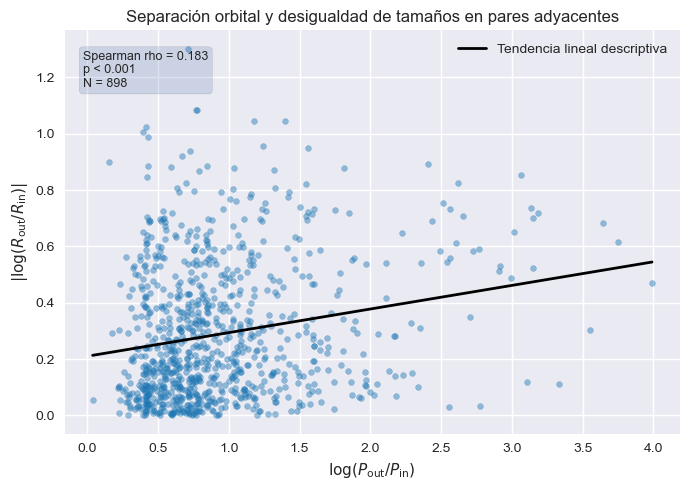

In [69]:
plt.figure(figsize=(7, 5))

plt.scatter(
    df_pares_corr["log_period_ratio"],
    df_pares_corr["abs_log_radius_ratio"],
    s=18,
    alpha=0.45,
    color="tab:blue"
)

coef = np.polyfit(
    df_pares_corr["log_period_ratio"],
    df_pares_corr["abs_log_radius_ratio"],
    1
)

x_line = np.linspace(
    df_pares_corr["log_period_ratio"].min(),
    df_pares_corr["log_period_ratio"].max(),
    100
)

y_line = coef[0] * x_line + coef[1]

plt.plot(
    x_line,
    y_line,
    color="black",
    linewidth=2,
    label="Tendencia lineal descriptiva"
)

plt.xlabel(r"$\log(P_\mathrm{out}/P_\mathrm{in})$")
plt.ylabel(r"$|\log(R_\mathrm{out}/R_\mathrm{in})|$")
plt.title("Separación orbital y desigualdad de tamaños en pares adyacentes")

plt.text(
    0.03,
    0.95,
    f"Spearman rho = {rho_pair:.3f}\np < 0.001\nN = {len(df_pares_corr)}",
    transform=plt.gca().transAxes,
    va="top",
    fontsize=9,
    bbox=dict(boxstyle="round", alpha=0.2)
)

plt.legend()
plt.tight_layout()
plt.savefig("../figures/fig_pares_log_period_ratio_vs_abs_log_radius_ratio.png", dpi=300)
plt.show()

In [70]:
df_pares = df_pares.merge(
    df_sistemas_enriquecido[["hostname", "gapped"]],
    on="hostname",
    how="left"
)

df_pares[["hostname", "abs_log_radius_ratio", "gapped"]].head()

,hostname,abs_log_radius_ratio,gapped
0,55 Cnc B,0.245380,0.0
1,AU Mic,1.006239,0.0
2,CoRoT-7,0.520680,0.0
3,DMPP-6,0.494910,0.0
4,EPIC 206024342,0.194156,0.0


In [71]:
tabla_pares_gapped = (
    df_pares
    .groupby("gapped")["abs_log_radius_ratio"]
    .agg(
        N="count",
        mediana="median",
        Q1=lambda x: x.quantile(0.25),
        Q3=lambda x: x.quantile(0.75),
        minimo="min",
        maximo="max"
    )
)

tabla_pares_gapped["IQR"] = tabla_pares_gapped["Q3"] - tabla_pares_gapped["Q1"]

tabla_pares_gapped = tabla_pares_gapped[
    ["N", "mediana", "Q1", "Q3", "IQR", "minimo", "maximo"]
].round(4)

tabla_pares_gapped

,N,mediana,Q1,Q3,IQR,minimo,maximo
gapped,,,,,,,
0.0,792,0.2093,0.0924,0.4233,0.3309,0.0,1.3015
1.0,106,0.3048,0.1181,0.5579,0.4398,0.0,0.8928


In [72]:
from scipy.stats import mannwhitneyu

pares_no_gap = df_pares[df_pares["gapped"] == 0]["abs_log_radius_ratio"].dropna()
pares_gap = df_pares[df_pares["gapped"] == 1]["abs_log_radius_ratio"].dropna()

U_pares, p_pares_mw = mannwhitneyu(
    pares_no_gap,
    pares_gap,
    alternative="two-sided"
)

n0_pares = len(pares_no_gap)
n1_pares = len(pares_gap)

# Tamaño de efecto rank-biserial
# Orientación: positivo si gapped=1 tiende a tener mayor desigualdad de radios
rank_biserial_pares = (2 * U_pares) / (n0_pares * n1_pares) - 1
rank_biserial_pares = -rank_biserial_pares

tabla_mannwhitney_pares_gapped = pd.DataFrame({
    "comparacion": ["abs_log_radius_ratio_gapped_0_vs_1"],
    "N_pares_gapped_0": [n0_pares],
    "N_pares_gapped_1": [n1_pares],
    "mediana_gapped_0": [pares_no_gap.median()],
    "mediana_gapped_1": [pares_gap.median()],
    "diferencia_mediana_1_menos_0": [
        pares_gap.median() - pares_no_gap.median()
    ],
    "U": [U_pares],
    "p_value": [p_pares_mw],
    "rank_biserial": [rank_biserial_pares]
})

tabla_mannwhitney_pares_gapped.round(6)

,comparacion,N_pares_gapped_0,N_pares_gapped_1,mediana_gapped_0,mediana_gapped_1,diferencia_mediana_1_menos_0,U,p_value,rank_biserial
0,abs_log_radius_ratio_gapped_0_vs_1,792,106,0.20934,0.30479,0.095451,34942.0,0.005038,0.167572


In [73]:
tabla_pares_gapped.to_csv(
    "../tables/tabla_abs_log_radius_ratio_por_gapped.csv"
)

tabla_mannwhitney_pares_gapped.to_csv(
    "../tables/tabla_mannwhitney_abs_log_radius_ratio_gapped.csv",
    index=False
)

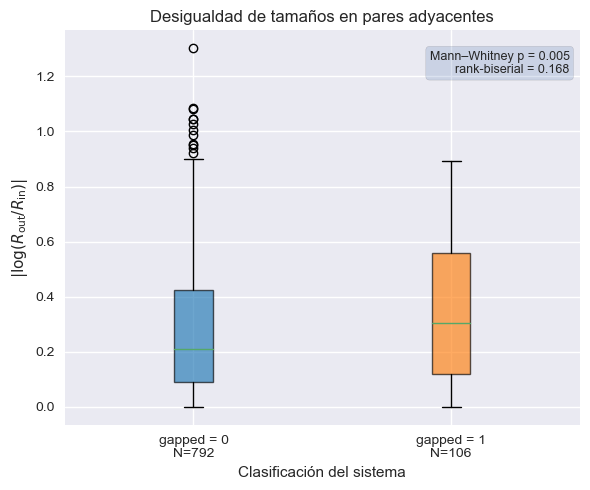

In [74]:
datos_pares_gapped = [
    df_pares[df_pares["gapped"] == 0]["abs_log_radius_ratio"].dropna(),
    df_pares[df_pares["gapped"] == 1]["abs_log_radius_ratio"].dropna()
]

labels_pares_gapped = [
    f"gapped = 0\nN={len(datos_pares_gapped[0])}",
    f"gapped = 1\nN={len(datos_pares_gapped[1])}"
]

plt.figure(figsize=(6, 5))

box = plt.boxplot(
    datos_pares_gapped,
    labels=labels_pares_gapped,
    patch_artist=True,
    showfliers=True
)

colores = ["tab:blue", "tab:orange"]

for patch, color in zip(box["boxes"], colores):
    patch.set_facecolor(color)
    patch.set_alpha(0.65)

plt.ylabel(r"$|\log(R_\mathrm{out}/R_\mathrm{in})|$")
plt.xlabel("Clasificación del sistema")
plt.title("Desigualdad de tamaños en pares adyacentes")

plt.text(
    0.98,
    0.95,
    f"Mann–Whitney p = {p_pares_mw:.3f}\nrank-biserial = {rank_biserial_pares:.3f}",
    transform=plt.gca().transAxes,
    ha="right",
    va="top",
    fontsize=9,
    bbox=dict(boxstyle="round", alpha=0.2)
)

plt.tight_layout()
plt.savefig("../figures/fig_abs_log_radius_ratio_por_gapped.png", dpi=300)
plt.show()

In [75]:
from scipy.stats import spearmanr

df_uniformidad_met = df_sistemas_enriquecido[
    df_sistemas_enriquecido["st_met"].notna() &
    df_sistemas_enriquecido["median_abs_log_radius_ratio"].notna()
].copy()

rho_met_uniform, p_met_uniform = spearmanr(
    df_uniformidad_met["st_met"],
    df_uniformidad_met["median_abs_log_radius_ratio"]
)

print(f"N sistemas = {len(df_uniformidad_met)}")
print(f"Spearman rho = {rho_met_uniform:.4f}")
print(f"p-value = {p_met_uniform:.4e}")

N sistemas = 615
Spearman rho = 0.1225
p-value = 2.3456e-03


In [76]:
tabla_spearman_met_uniformidad = pd.DataFrame({
    "analisis": ["st_met_vs_median_abs_log_radius_ratio"],
    "N": [len(df_uniformidad_met)],
    "spearman_rho": [rho_met_uniform],
    "p_value": [p_met_uniform]
})

tabla_spearman_met_uniformidad.to_csv(
    "../tables/tabla_spearman_metalicidad_uniformidad.csv",
    index=False
)

tabla_spearman_met_uniformidad

,analisis,N,spearman_rho,p_value
0,st_met_vs_median_abs_log_radius_ratio,615,0.122476,0.002346


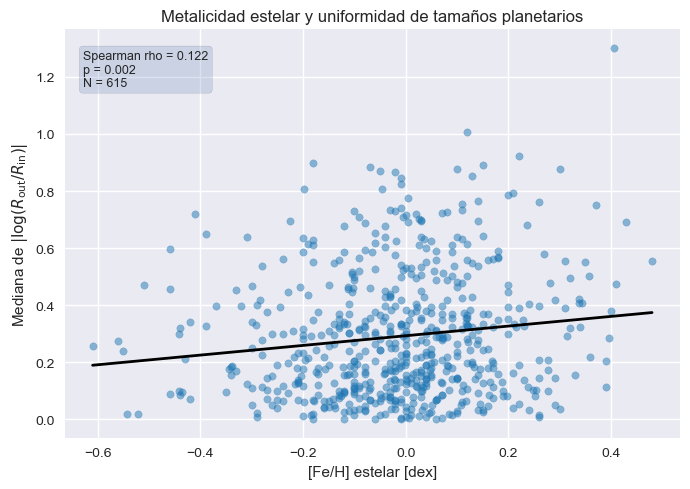

In [78]:
plt.figure(figsize=(7, 5))

plt.scatter(
    df_uniformidad_met["st_met"],
    df_uniformidad_met["median_abs_log_radius_ratio"],
    s=28,
    alpha=0.5,
    color="tab:blue"
)

coef = np.polyfit(
    df_uniformidad_met["st_met"],
    df_uniformidad_met["median_abs_log_radius_ratio"],
    1
)

x_line = np.linspace(
    df_uniformidad_met["st_met"].min(),
    df_uniformidad_met["st_met"].max(),
    100
)

y_line = coef[0] * x_line + coef[1]

plt.plot(
    x_line,
    y_line,
    color="black",
    linewidth=2
)

plt.xlabel("[Fe/H] estelar [dex]")
plt.ylabel(r"Mediana de $|\log(R_\mathrm{out}/R_\mathrm{in})|$")
plt.title("Metalicidad estelar y uniformidad de tamaños planetarios")

plt.text(
    0.03,
    0.95,
    f"Spearman rho = {rho_met_uniform:.3f}\np = {p_met_uniform:.3f}\nN = {len(df_uniformidad_met)}",
    transform=plt.gca().transAxes,
    va="top",
    fontsize=9,
    bbox=dict(boxstyle="round", alpha=0.2)
)

plt.tight_layout()
plt.savefig("../figures/fig_metalicidad_vs_uniformidad_radios.png", dpi=300)
plt.show()
  

La relación visual es débil, con mucha dispersión, pero la tendencia promedio es positiva. Esto coincide con Spearman rho = 0.123, p = 0.002. En la muestra, sistemas más metálicos tienden a tener planetas adyacentes ligeramente menos uniformes en radio.

La metalicidad no mostró una asociación clara con el espaciamiento orbital, pero sí aparece débilmente asociada con la uniformidad de tamaños. Los sistemas más metálicos tienden a presentar planetas adyacentes ligeramente menos similares en radio y, en sistemas con tres o más planetas, una mayor dispersión relativa de radios.

In [79]:
df_radius_cv_met = df_sistemas_enriquecido[
    df_sistemas_enriquecido["st_met"].notna() &
    df_sistemas_enriquecido["radius_cv"].notna()
].copy()

rho_met_radius_cv, p_met_radius_cv = spearmanr(
    df_radius_cv_met["st_met"],
    df_radius_cv_met["radius_cv"]
)

print(f"N sistemas = {len(df_radius_cv_met)}")
print(f"Spearman rho = {rho_met_radius_cv:.4f}")
print(f"p-value = {p_met_radius_cv:.4e}")

N sistemas = 200
Spearman rho = 0.1696
p-value = 1.6356e-02


In [80]:
tabla_spearman_met_uniformidad_extra = pd.DataFrame({
    "analisis": [
        "st_met_vs_median_abs_log_radius_ratio",
        "st_met_vs_radius_cv_N_ge_3"
    ],
    "N": [
        len(df_uniformidad_met),
        len(df_radius_cv_met)
    ],
    "spearman_rho": [
        rho_met_uniform,
        rho_met_radius_cv
    ],
    "p_value": [
        p_met_uniform,
        p_met_radius_cv
    ]
})

tabla_spearman_met_uniformidad_extra.to_csv(
    "../tables/tabla_spearman_metalicidad_uniformidad_completa.csv",
    index=False
)

tabla_spearman_met_uniformidad_extra

,analisis,N,spearman_rho,p_value
0,st_met_vs_median_abs_log_radius_ratio,615,0.122476,0.002346
1,st_met_vs_radius_cv_N_ge_3,200,0.169599,0.016356


In [81]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

df_modelo = df_sistemas_enriquecido[
    df_sistemas_enriquecido["median_period_ratio"].notna() &
    df_sistemas_enriquecido["st_met"].notna() &
    df_sistemas_enriquecido["st_mass"].notna() &
    df_sistemas_enriquecido["median_radius"].notna() &
    df_sistemas_enriquecido["N_planetas"].notna()
].copy()

df_modelo["log_median_period_ratio"] = np.log10(df_modelo["median_period_ratio"])

df_modelo = df_modelo[
    [
        "hostname",
        "log_median_period_ratio",
        "median_period_ratio",
        "st_met",
        "st_mass",
        "median_radius",
        "N_planetas",
        "gapped"
    ]
].copy()

df_modelo.shape

(615, 8)

In [82]:
X = df_modelo[
    [
        "st_met",
        "st_mass",
        "median_radius",
        "N_planetas"
    ]
]

X = sm.add_constant(X)

y = df_modelo["log_median_period_ratio"]

modelo_ols = sm.OLS(y, X).fit()

modelo_ols.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                               OLS Regression Results                              
===================================================================================
Dep. Variable:     log_median_period_ratio   R-squared:                       0.093
Model:                                 OLS   Adj. R-squared:                  0.087
Method:                      Least Squares   F-statistic:                     15.58
Date:                     Mon, 17 Aug 2026   Prob (F-statistic):           3.79e-12
Time:                             09:05:02   Log-Likelihood:                -14.570
No. Observations:                      615   AIC:                             39.14
Df Residuals:                          610   BIC:                             61.25
Df Model:                                4                                         
Covariance Type:                 nonrobust                                         
=================================================================================
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const             0.7046      0.058     12.208      0.000       0.591       0.818
st_met            0.0843      0.061      1.386      0.166      -0.035       0.204
st_mass          -0.1715      0.044     -3.908      0.000      -0.258      -0.085
median_radius     0.0465      0.018      2.553      0.011       0.011       0.082
N_planetas       -0.0867      0.013     -6.673      0.000      -0.112      -0.061
==============================================================================
Omnibus:                      219.205   Durbin-Watson:                   1.953
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              721.283
Skew:                           1.700   Prob(JB):                    2.37e-157
Kurtosis:                       7.072   Cond. No.                         25.1
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

En el modelo multivariable, [Fe/H] no mantiene una asociación significativa con el espaciamiento orbital mediano una vez controladas la masa estelar, el radio planetario mediano y la multiplicidad del sistema. En cambio, la masa estelar, el radio planetario mediano y el número de planetas sí aparecen asociados con log10(median_period_ratio).

La arquitectura sí se relaciona débilmente con otras propiedades del sistema, especialmente N_planetas, st_mass y median_radius.

In [83]:
tabla_modelo_ols = pd.DataFrame({
    "variable": modelo_ols.params.index,
    "coef": modelo_ols.params.values,
    "std_err": modelo_ols.bse.values,
    "t": modelo_ols.tvalues.values,
    "p_value": modelo_ols.pvalues.values,
    "IC95_low": modelo_ols.conf_int()[0].values,
    "IC95_high": modelo_ols.conf_int()[1].values
})

tabla_modelo_ols.to_csv(
    "../tables/tabla_modelo_ols_log_median_period_ratio.csv",
    index=False
)

tabla_modelo_ols

,variable,coef,std_err,t,p_value,IC95_low,IC95_high
0,const,0.704587,0.057714,12.208267,8.022074e-31,0.591245,0.817929
1,st_met,0.084324,0.060860,1.385524,1.663987e-01,-0.035198,0.203845
2,st_mass,-0.171517,0.043889,-3.907940,1.035079e-04,-0.257710,-0.085325
3,median_radius,0.046547,0.018232,2.552978,1.092292e-02,0.010741,0.082353
4,N_planetas,-0.086727,0.012996,-6.673360,5.621049e-11,-0.112249,-0.061204


No se encontró evidencia de multicolinealidad importante entre los predictores del modelo. Todos los VIF de las variables explicativas fueron cercanos a 1, lo que indica que las estimaciones de los coeficientes no están dominadas por correlaciones fuertes entre predictores.

In [84]:
X_vif = df_modelo[
    [
        "st_met",
        "st_mass",
        "median_radius",
        "N_planetas"
    ]
].copy()

X_vif = sm.add_constant(X_vif)

tabla_vif = pd.DataFrame({
    "variable": X_vif.columns,
    "VIF": [
        variance_inflation_factor(X_vif.values, i)
        for i in range(X_vif.shape[1])
    ]
})

tabla_vif

,variable,VIF
0,const,33.096876
1,st_met,1.112763
2,st_mass,1.178467
3,median_radius,1.101536
4,N_planetas,1.000840


In [85]:
# Modelo completo: incluye [Fe/H]
X_full = df_modelo[
    ["st_met", "st_mass", "median_radius", "N_planetas"]
]
X_full = sm.add_constant(X_full)

modelo_full = sm.OLS(
    df_modelo["log_median_period_ratio"],
    X_full
).fit()


# Modelo reducido: sin [Fe/H]
X_reducido = df_modelo[
    ["st_mass", "median_radius", "N_planetas"]
]
X_reducido = sm.add_constant(X_reducido)

modelo_reducido = sm.OLS(
    df_modelo["log_median_period_ratio"],
    X_reducido
).fit()


comparacion_modelos_spacing = pd.DataFrame({
    "modelo": [
        "completo_con_st_met",
        "reducido_sin_st_met"
    ],
    "N": [
        int(modelo_full.nobs),
        int(modelo_reducido.nobs)
    ],
    "R2": [
        modelo_full.rsquared,
        modelo_reducido.rsquared
    ],
    "R2_ajustado": [
        modelo_full.rsquared_adj,
        modelo_reducido.rsquared_adj
    ],
    "AIC": [
        modelo_full.aic,
        modelo_reducido.aic
    ],
    "BIC": [
        modelo_full.bic,
        modelo_reducido.bic
    ]
})

comparacion_modelos_spacing.round(6)

,modelo,N,R2,R2_ajustado,AIC,BIC
0,completo_con_st_met,615,0.092712,0.086763,39.140953,61.249064
1,reducido_sin_st_met,615,0.089857,0.085388,39.073325,56.759815


Al comparar el modelo completo con un modelo reducido sin [Fe/H], se observa que la inclusión de la metalicidad estelar no mejora de forma apreciable el ajuste. El R² ajustado cambia solo de 0.085 a 0.087, mientras que el BIC es menor para el modelo reducido. Esto sugiere que [Fe/H] no aporta información adicional relevante para explicar log10(median_period_ratio) una vez consideradas la masa estelar, el radio planetario mediano y la multiplicidad del sistema.

In [86]:
df_modelo_gap = df_sistemas_enriquecido[
    df_sistemas_enriquecido["gapped"].notna() &
    df_sistemas_enriquecido["st_met"].notna() &
    df_sistemas_enriquecido["st_mass"].notna() &
    df_sistemas_enriquecido["median_radius"].notna()
].copy()

X_gap = df_modelo_gap[
    [
        "st_met",
        "st_mass",
        "median_radius"
    ]
]

X_gap = sm.add_constant(X_gap)

y_gap = df_modelo_gap["gapped"]

modelo_logit_controlado = sm.Logit(y_gap, X_gap).fit()

modelo_logit_controlado.summary()

Optimization terminated successfully.
         Current function value: 0.393172
         Iterations 6


<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:                 gapped   No. Observations:                  615
Model:                          Logit   Df Residuals:                      611
Method:                           MLE   Df Model:                            3
Date:                Mon, 17 Aug 2026   Pseudo R-squ.:                 0.02124
Time:                        09:09:25   Log-Likelihood:                -241.80
converged:                       True   LL-Null:                       -247.05
Covariance Type:            nonrobust   LLR p-value:                   0.01481
=================================================================================
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
const            -0.8419      0.515     -1.636      0.102      -1.851       0.167
st_met            1.5699      0.725      2.166      0.030       0.149       2.991
st_mass          -1.4349      0.497     -2.889      0.004      -2.408      -0.462
median_radius     0.0981      0.218      0.451      0.652      -0.328       0.524
=================================================================================
"""

[Fe/H] no se relacionaba claramente con gapped en el modelo simple,
pero al controlar por st_mass y median_radius sí aparece una asociación positiva.

En el modelo logístico controlado, la metalicidad estelar aparece asociada positivamente con la probabilidad de presentar huecos orbitales amplios, mientras que la masa estelar aparece asociada negativamente. Sin embargo, el poder explicativo global del modelo es bajo, por lo que este resultado debe interpretarse como una señal débil y no como evidencia causal.


In [ ]:
params = modelo_logit_controlado.params
conf = modelo_logit_controlado.conf_int()

tabla_or_logit_controlado = pd.DataFrame({
    "variable": params.index,
    "coef": params.values,
    "p_value": modelo_logit_controlado.pvalues.values,
    "odds_ratio": np.exp(params.values),
    "OR_IC95_low": np.exp(conf[0].values),
    "OR_IC95_high": np.exp(conf[1].values)
})

tabla_or_logit_controlado.to_csv(
    "../tables/tabla_logit_controlado_gapped_odds_ratios.csv",
    index=False
)

tabla_or_logit_controlado.round(4)

En el modelo logístico multivariable, la metalicidad estelar aparece asociada positivamente con la probabilidad de que un sistema presente huecos orbitales amplios, una vez controladas la masa estelar y el radio planetario mediano (OR = 4.81, IC95% = [1.16, 19.90], p = 0.030). La masa estelar muestra una asociación negativa significativa (OR = 0.24, IC95% = [0.09, 0.63], p = 0.004), mientras que el radio planetario mediano no presenta una asociación significativa. Sin embargo, el bajo pseudo R² del modelo indica que estas variables explican solo una fracción pequeña de la variación observada.

La asociación de [Fe/H] con gapped aparece solo al controlar por otras propiedades del sistema, especialmente la masa estelar.


In [88]:
tabla_resumen_logit_controlado = pd.DataFrame({
    "modelo": ["gapped ~ st_met + st_mass + median_radius"],
    "N": [int(modelo_logit_controlado.nobs)],
    "pseudo_R2": [modelo_logit_controlado.prsquared],
    "LLR_p_value": [modelo_logit_controlado.llr_pvalue],
    "AIC": [modelo_logit_controlado.aic],
    "BIC": [modelo_logit_controlado.bic]
})

tabla_resumen_logit_controlado.to_csv(
    "../tables/resumen_modelo_logit_controlado_gapped.csv",
    index=False
)

tabla_resumen_logit_controlado


,modelo,N,pseudo_R2,LLR_p_value,AIC,BIC
0,gapped ~ st_met + st_mass + median_radius,615,0.021237,0.014808,491.602055,509.288544


In [89]:
tabla_resultados_principales = pd.DataFrame({
    "bloque": [
        "Metalicidad y espaciamiento",
        "Metalicidad y gaps",
        "Masa estelar y arquitectura",
        "Masa estelar y gaps",
        "Pares adyacentes",
        "Gapped y uniformidad",
        "Metalicidad y uniformidad",
        "Metalicidad y uniformidad",
        "Modelo multivariable spacing",
        "Modelo logístico gapped"
    ],
    "pregunta": [
        "[Fe/H] vs median_period_ratio",
        "[Fe/H] entre sistemas gapped y non-gapped",
        "st_mass vs variables de arquitectura",
        "st_mass entre sistemas gapped y non-gapped",
        "Separación orbital vs desigualdad de radios",
        "Desigualdad de radios en gapped vs non-gapped",
        "[Fe/H] vs median_abs_log_radius_ratio",
        "[Fe/H] vs radius_cv en sistemas con N>=3",
        "log10(median_period_ratio) ~ [Fe/H] + st_mass + median_radius + N_planetas",
        "gapped ~ [Fe/H] + st_mass + median_radius"
    ],
    "N": [
        615,
        615,
        615,
        615,
        898,
        898,
        615,
        200,
        615,
        615
    ],
    "resultado_cuantitativo": [
        "Spearman rho = 0.024, p = 0.558; IC95% bootstrap = [-0.054, 0.101]",
        "Mann-Whitney p = 0.335; diferencia de medianas = 0.016 dex; rank-biserial = 0.065",
        "rho = -0.110 a -0.138; p = 0.006 a 0.001",
        "Mann-Whitney p = 0.015; diferencia de medianas = -0.036 M_sun; rank-biserial = -0.164",
        "Spearman rho = 0.183, p < 0.001",
        "Mann-Whitney p = 0.005; diferencia de medianas = 0.095; rank-biserial = 0.168",
        "Spearman rho = 0.123, p = 0.002",
        "Spearman rho = 0.170, p = 0.016",
        "st_met: coef = 0.084, p = 0.166; R2 ajustado = 0.087",
        "st_met: OR = 4.81, IC95% = [1.16, 19.90], p = 0.030; pseudo R2 = 0.021"
    ],
    "interpretacion": [
        "No hay evidencia de asociación entre metalicidad y espaciamiento orbital mediano.",
        "No hay evidencia de diferencia clara de metalicidad entre sistemas con y sin huecos amplios.",
        "La masa estelar muestra una asociación negativa débil con el espaciamiento orbital.",
        "Los sistemas gapped tienden a orbitar estrellas ligeramente menos masivas; efecto pequeño.",
        "Pares más separados orbitalmente tienden a tener planetas menos similares en tamaño.",
        "Los sistemas gapped presentan pares adyacentes más desiguales en radio.",
        "Sistemas más metálicos tienden a tener planetas adyacentes ligeramente menos uniformes.",
        "En sistemas con N>=3, mayor metalicidad se asocia con mayor dispersión relativa de radios.",
        "[Fe/H] no aporta información adicional relevante para explicar el espaciamiento al controlar por otras variables.",
        "[Fe/H] aparece asociado con gapped solo en el modelo controlado; resultado débil y con incertidumbre amplia."
    ],
    "estado": [
        "cerrado",
        "cerrado",
        "cerrado",
        "cerrado",
        "cerrado",
        "cerrado",
        "cerrado",
        "cerrado",
        "cerrado",
        "cerrado"
    ]
})

tabla_resultados_principales.to_csv(
    "../tables/tabla_resultados_principales.csv",
    index=False
)

tabla_resultados_principales

,bloque,pregunta,N,resultado_cuantitativo,interpretacion,estado
0,Metalicidad y espaciamiento,[Fe/H] vs median_period_ratio,615,"Spearman rho = 0.024, p = 0.558; IC95% bootstr...",No hay evidencia de asociación entre metalicid...,cerrado
1,Metalicidad y gaps,[Fe/H] entre sistemas gapped y non-gapped,615,Mann-Whitney p = 0.335; diferencia de medianas...,No hay evidencia de diferencia clara de metali...,cerrado
2,Masa estelar y arquitectura,st_mass vs variables de arquitectura,615,rho = -0.110 a -0.138; p = 0.006 a 0.001,La masa estelar muestra una asociación negativ...,cerrado
3,Masa estelar y gaps,st_mass entre sistemas gapped y non-gapped,615,Mann-Whitney p = 0.015; diferencia de medianas...,Los sistemas gapped tienden a orbitar estrella...,cerrado
4,Pares adyacentes,Separación orbital vs desigualdad de radios,898,"Spearman rho = 0.183, p < 0.001",Pares más separados orbitalmente tienden a ten...,cerrado
5,Gapped y uniformidad,Desigualdad de radios en gapped vs non-gapped,898,Mann-Whitney p = 0.005; diferencia de medianas...,Los sistemas gapped presentan pares adyacentes...,cerrado
6,Metalicidad y uniformidad,[Fe/H] vs median_abs_log_radius_ratio,615,"Spearman rho = 0.123, p = 0.002",Sistemas más metálicos tienden a tener planeta...,cerrado
7,Metalicidad y uniformidad,[Fe/H] vs radius_cv en sistemas con N>=3,200,"Spearman rho = 0.170, p = 0.016","En sistemas con N>=3, mayor metalicidad se aso...",cerrado
8,Modelo multivariable spacing,log10(median_period_ratio) ~ [Fe/H] + st_mass ...,615,"st_met: coef = 0.084, p = 0.166; R2 ajustado =...",[Fe/H] no aporta información adicional relevan...,cerrado
9,Modelo logístico gapped,gapped ~ [Fe/H] + st_mass + median_radius,615,"st_met: OR = 4.81, IC95% = [1.16, 19.90], p = ...",[Fe/H] aparece asociado con gapped solo en el ...,cerrado


In [90]:
tabla_resultados_consolidados = pd.DataFrame({
    "analisis": [
        "[Fe/H] vs spacing continuo",
        "[Fe/H] vs gapped",
        "Mstar vs spacing continuo",
        "Mstar vs gapped",
        "Spacing vs desigualdad de radios",
        "Gapped vs uniformidad de radios",
        "[Fe/H] vs uniformidad: pares adyacentes",
        "[Fe/H] vs uniformidad: radius_cv",
        "Modelo OLS spacing controlado",
        "Modelo logístico gapped controlado"
    ],

    "pregunta": [
        "¿La metalicidad se asocia con el espaciamiento orbital mediano?",
        "¿La metalicidad difiere entre sistemas gapped y non-gapped?",
        "¿La masa estelar se asocia con métricas de arquitectura orbital?",
        "¿La masa estelar difiere entre sistemas gapped y non-gapped?",
        "¿Pares más separados orbitalmente son menos similares en radio?",
        "¿Los sistemas gapped tienen pares planetarios menos uniformes?",
        "¿La metalicidad se asocia con menor uniformidad de radios adyacentes?",
        "¿La metalicidad se asocia con mayor dispersión relativa de radios en sistemas N>=3?",
        "¿[Fe/H] explica spacing al controlar por Mstar, radio mediano y Nplanetas?",
        "¿[Fe/H] predice gapped al controlar por Mstar y radio mediano?"
    ],

    "N": [
        615,
        615,
        615,
        615,
        898,
        898,
        615,
        200,
        615,
        615
    ],

    "metodo": [
        "Spearman + bootstrap",
        "Mann-Whitney + logit simple",
        "Spearman",
        "Mann-Whitney",
        "Spearman",
        "Mann-Whitney",
        "Spearman",
        "Spearman",
        "OLS multivariable",
        "Logit multivariable"
    ],

    "estadistico_o_coeficiente": [
        "rho = 0.0237",
        "diff mediana = 0.016 dex; rank-biserial = 0.065; logit coef = 0.981",
        "rho = -0.110 a -0.138",
        "diff mediana = -0.036 M_sun; rank-biserial = -0.164",
        "rho = 0.1826",
        "diff mediana = 0.095; rank-biserial = 0.168",
        "rho = 0.1225",
        "rho = 0.1696",
        "coef [Fe/H] = 0.0843",
        "coef [Fe/H] = 1.5699; OR = 4.806"
    ],

    "IC95": [
        "rho bootstrap IC95% = [-0.0544, 0.1008]",
        "logit OR IC95% = [0.695, 10.243]",
        "no calculado todavía",
        "no calculado todavía",
        "no calculado todavía",
        "no calculado todavía",
        "no calculado todavía",
        "no calculado todavía",
        "coef [Fe/H] IC95% = [-0.035, 0.204]",
        "OR [Fe/H] IC95% = [1.161, 19.899]"
    ],

    "p_value": [
        0.558,
        0.335,
        "0.006 a 0.001",
        0.015,
        3.5888e-08,
        0.005038,
        0.0023456,
        0.016356,
        0.166,
        0.0303
    ],

    "tamano_efecto": [
        "nulo / despreciable",
        "pequeño; resultado simple no significativo",
        "pequeño",
        "pequeño",
        "pequeño-moderado para muestra observacional",
        "pequeño",
        "pequeño",
        "pequeño",
        "sin efecto significativo de [Fe/H]",
        "OR alto pero IC amplio; señal débil/inestable"
    ],

    "interpretacion": [
        "No hay evidencia de asociación entre metalicidad y espaciamiento orbital mediano.",
        "La metalicidad no difiere claramente entre sistemas gapped y non-gapped en análisis simple; la señal es débil e inestable.",
        "La masa estelar muestra asociaciones negativas débiles con el espaciamiento orbital.",
        "Los sistemas gapped tienden a orbitar estrellas ligeramente menos masivas; efecto pequeño.",
        "Los pares más separados orbitalmente tienden a tener planetas menos similares en radio.",
        "Los sistemas gapped presentan pares adyacentes más desiguales en radio.",
        "Sistemas más metálicos tienden a tener planetas adyacentes ligeramente menos uniformes.",
        "En sistemas con N>=3, mayor metalicidad se asocia débilmente con mayor dispersión relativa de radios.",
        "[Fe/H] no aporta información adicional relevante para explicar el spacing una vez controladas otras variables.",
        "[Fe/H] aparece asociado con gapped solo en modelo controlado; resultado prometedor pero débil por pseudo R2 bajo e IC amplio."
    ],

    "clasificacion": [
        "C",
        "C",
        "B",
        "B",
        "A",
        "A",
        "B",
        "B",
        "C",
        "B"
    ],

    "decision": [
        "Conservar como resultado nulo informativo.",
        "Conservar con cautela; no usar como resultado principal.",
        "Conservar como resultado secundario.",
        "Conservar como resultado secundario.",
        "Usar como potencial resultado principal.",
        "Usar como potencial resultado principal.",
        "Conservar como resultado secundario interesante.",
        "Conservar como resultado secundario; muestra menor.",
        "Usar para apoyar que metalicidad-spacing es nulo.",
        "Conservar como resultado secundario/modelo exploratorio; no sobrerreclamar."
    ]
})

tabla_resultados_consolidados.to_csv(
    "../tables/tabla_resultados_consolidados.csv",
    index=False
)

tabla_resultados_consolidados

,analisis,pregunta,N,metodo,estadistico_o_coeficiente,IC95,p_value,tamano_efecto,interpretacion,clasificacion,decision
0,[Fe/H] vs spacing continuo,¿La metalicidad se asocia con el espaciamiento...,615,Spearman + bootstrap,rho = 0.0237,"rho bootstrap IC95% = [-0.0544, 0.1008]",0.558,nulo / despreciable,No hay evidencia de asociación entre metalicid...,C,Conservar como resultado nulo informativo.
1,[Fe/H] vs gapped,¿La metalicidad difiere entre sistemas gapped ...,615,Mann-Whitney + logit simple,diff mediana = 0.016 dex; rank-biserial = 0.06...,"logit OR IC95% = [0.695, 10.243]",0.335,pequeño; resultado simple no significativo,La metalicidad no difiere claramente entre sis...,C,Conservar con cautela; no usar como resultado ...
2,Mstar vs spacing continuo,¿La masa estelar se asocia con métricas de arq...,615,Spearman,rho = -0.110 a -0.138,no calculado todavía,0.006 a 0.001,pequeño,La masa estelar muestra asociaciones negativas...,B,Conservar como resultado secundario.
3,Mstar vs gapped,¿La masa estelar difiere entre sistemas gapped...,615,Mann-Whitney,diff mediana = -0.036 M_sun; rank-biserial = -...,no calculado todavía,0.015,pequeño,Los sistemas gapped tienden a orbitar estrella...,B,Conservar como resultado secundario.
4,Spacing vs desigualdad de radios,¿Pares más separados orbitalmente son menos si...,898,Spearman,rho = 0.1826,no calculado todavía,0.0,pequeño-moderado para muestra observacional,Los pares más separados orbitalmente tienden a...,A,Usar como potencial resultado principal.
5,Gapped vs uniformidad de radios,¿Los sistemas gapped tienen pares planetarios ...,898,Mann-Whitney,diff mediana = 0.095; rank-biserial = 0.168,no calculado todavía,0.005038,pequeño,Los sistemas gapped presentan pares adyacentes...,A,Usar como potencial resultado principal.
6,[Fe/H] vs uniformidad: pares adyacentes,¿La metalicidad se asocia con menor uniformida...,615,Spearman,rho = 0.1225,no calculado todavía,0.002346,pequeño,Sistemas más metálicos tienden a tener planeta...,B,Conservar como resultado secundario interesante.
7,[Fe/H] vs uniformidad: radius_cv,¿La metalicidad se asocia con mayor dispersión...,200,Spearman,rho = 0.1696,no calculado todavía,0.016356,pequeño,"En sistemas con N>=3, mayor metalicidad se aso...",B,Conservar como resultado secundario; muestra m...
8,Modelo OLS spacing controlado,¿[Fe/H] explica spacing al controlar por Mstar...,615,OLS multivariable,coef [Fe/H] = 0.0843,"coef [Fe/H] IC95% = [-0.035, 0.204]",0.166,sin efecto significativo de [Fe/H],[Fe/H] no aporta información adicional relevan...,C,Usar para apoyar que metalicidad-spacing es nulo.
9,Modelo logístico gapped controlado,¿[Fe/H] predice gapped al controlar por Mstar ...,615,Logit multivariable,coef [Fe/H] = 1.5699; OR = 4.806,"OR [Fe/H] IC95% = [1.161, 19.899]",0.0303,OR alto pero IC amplio; señal débil/inestable,[Fe/H] aparece asociado con gapped solo en mod...,B,Conservar como resultado secundario/modelo exp...
